In [1]:
import lmdb
import cv2
import numpy as np
import skimage.metrics as skmetrics
import skimage.io as skio
# write a data loader
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
# from torchvision import transform, utils
import os
from typing import Union, Optional

In [ ]:
dataset_dir = "/u2/users/piz693/SIDD"
train_gt_dir = "train/gt_crops.lmdb"
train_noisy_dir = "train/input_crops.lmdb"
dataset_file = "data.mdb" # same for both input and ground truth
label_file = "meta_info.txt" # same for both input and ground truth

In [ ]:
full_train_dataset_path = os.path.join(
    dataset_dir, 
    train_noisy_dir
)

env = lmdb.open(
    full_train_dataset_path,
    readonly=True,
    lock=False,
    readahead=False,
    meminit=False
)

In [ ]:
import time
with env.begin() as transaction:
    number_of_entries = transaction.stat()["entries"]
    print(
        transaction.stat()
    )
    # extract all keys
    start = time.time()
    db_keys = list(transaction.cursor().iternext(values=False))
    end = time.time()
    print(end-start)
    # takes 0.21 seconds
    print(len(db_keys))
    # for i, (k, v ) in enumerate(transaction.cursor()):
    #     print(k.decode())
    #     # stop after 5
    #     if i==15:
    #         break
        # buf = transaction.get(k)
        # img = cv2.imdecode(
        #     np.frombuffer(buf, np.uint8),
        #     cv2.IMREAD_UNCHANGED
        # )

In [ ]:

with env.begin() as transaction:
    value = transaction.get(db_keys[-1])
    # img = cv2.imdecode(
    #     np.frombuffer(value, np.uint8),
    #     cv2.IMREAD_UNCHANGED
    # )
    with open(f"dataset/{db_keys[-1].decode()}.png", "wb") as f:
        f.write(value)

In [ ]:
type(db_keys[0])

In [ ]:

# we only have keys, lmdb environment
class ImageDataset(Dataset):
    def __init__(
            self, 
            noisy_path:Union[str, os.PathLike], 
            clean_path:Union[str, os.PathLike], 
            meta_path:Union[str, os.PathLike]
        ):
        """
        Initialize the class instance
        all paths are expected to be absolute
        Args:
            noisy_path: Absolute path to the database containing noisy images
            clean_path: Absolute path to the database containing ground truth images
            meta_path: Absolute path to the txt file containing labels, image dimensions and compression rates 
        """
        with open(meta_path) as f:
            self.keys = [label.split()[0] for label in f.readlines()]
        self.noisy_path = noisy_path
        self.clean_path = clean_path

        # lmdb environments (equivalent to database engines). We do lazy loading
        self.noisy_env = None
        self.clean_env = None

    def _open(self, dataset_path:Union[str, os.PathLike])->lmdb.Environment:
        return lmdb.open(
            dataset_path,     
            readonly=True,
            lock=False,
            readahead=False,
            meminit=False
        )

    def _read(self, env:lmdb.Environment, key:str):
        with env.begin() as transaction:
            buffer = transaction.get(key)
        img = cv2.imdecode(np.frombuffer(buffer, np.uint8), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        return torch.from_numpy(img).permute(2,0,1)

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, i:int):
        if self.noisy_env == None or self.clean_env == None:
            self.noisy_env = self._open(self.noisy_path)
            self.clean_env = self._open(self.clean_path)
        
        key = self.keys[i].decode()
        noisy_image = self._read(self.noisy_env, key)
        clean_image = self._read(self.clean_env, key)
        
        return noisy_image, clean_image

In [ ]:
dataset_dir = "/u2/users/piz693/SIDD"
train_gt_dir = "train/gt_crops.lmdb"
train_noisy_dir = "train/input_crops.lmdb"
dataset_file = "data.mdb" # same for both input and ground truth
label_file = "meta_info.txt" # same for both input and ground truth

dataset = ImageDataset(
    noisy_path = os.path.join(dataset_dir, train_noisy_dir),
    clean_path = os.path.join(dataset_dir, train_gt_dir),
    meta_path = os.path.join(dataset_dir, train_gt_dir, label_file)
)
dataloader = DataLoader(dataset, batch_size=4,
                        shuffle=True, num_workers=0)

In [ ]:
# generate 32? randomly selected non-overlapping image patches of size 256x256 from the images

# full images
uncropped_dataset_dir = "/u2/users/piz693/SIDD-small/SRGB"

# divide images in each instance into noisy/groundtruth pairs 
# crop those pairs using the same cropping mask for each pair

def crop_image(img, dim=256):
    """
    Crop high-res images into dimxdim patches. Generator
    """
    shape = img.shape
    horizontal_patches = shape[1] // dim
    vertical_patches = shape[0] // dim
    patch_id = 0
    print("SHAPE",shape)
    print("HORIZONTAL AND VERTICAL PATCH NUMBERS",horizontal_patches, vertical_patches)
    for vert_i in range(vertical_patches):
        for hor_i in range(horizontal_patches):
            patch = img[
                dim * hor_i: dim * (hor_i+1),
                dim * vert_i: dim * (vert_i+1),
                :
            ]
            yield patch, patch_id
            patch_id += 1
    print(f"Generated {patch_id+1} patches")

# store each patch as instanceID_patchID_{noise,gt}.png
# this way, each image can be accessed as ID_{noise,gt}.png
# rewrite the data loader to suppot this format


In [ ]:
image_instance_path = "/u2/users/piz693/SIDD-small/SRGB/train/Data/0150_007_S6_00100_00100_5500_L"
instance_id = "0150_007_S6_00100_00100_5500_L"
image_name = "0150_GT_SRGB_083.PNG"

image_path = os.path.join(image_instance_path, image_name)

img = skio.imread(
    image_path
)

# patches = crop_image(img)
# for patch_id, patch in enumerate(patches):
#     # instanceID_patchID_{noise,gt}.png
#     # cv2.imwrite(f"dataset/{instance_id}_{image_name[:-3]}_{patch_id}.png", patch)

Generated 221 patches


SHAPE (3000, 5328, 3)
HORIZONTAL AND VERTICAL PATCH NUMBERS 20 11


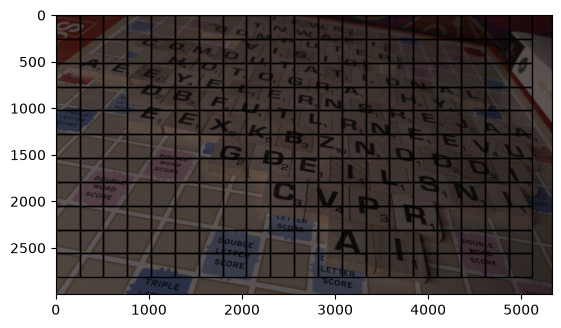

In [20]:
dim = 256
shape = img.shape
horizontal_patches = shape[1] // dim
vertical_patches = shape[0] // dim
patch_id = 0
print("SHAPE",shape)
print("HORIZONTAL AND VERTICAL PATCH NUMBERS",horizontal_patches, vertical_patches)

figure, ax = plt.subplots()
ax.imshow(img)
#   :                +------------------+
#   :                |                  |
#   :              height               |
#   :                |                  |
#   :               (xy)---- width -----+
for vert_i in range(vertical_patches):
    for hor_i in range(horizontal_patches):
        # print(dim * hor_i, dim * (hor_i+1))
        # print(dim * vert_i, dim * (vert_i+1))
        rect = plt.Rectangle(
        xy=(
            dim * hor_i, 
            dim * vert_i
        ),
        height = dim,
        width=dim,
        fill=False,
        color="black"
        )
        ax.add_patch(rect)